# Measurement noise on online and lab values

The simulator records exact process values. `MeasurementNoise` turns them into what a plant would actually
measure: probe noise, calibration offsets, drift, quantisation, instrument ranges and lab assay errors. This
notebook shows what the noise looks like and checks that it does what the documentation says:

1. measured vs exact values for every online channel,
2. each error source on its own (white noise, offset, drift, quantisation),
3. the statistics: residuals against the specified standard deviations, over many noise realisations,
4. off-gas rates (`OUR`, `CER`) recomputed from the measured gas,
5. lab results with assay error,
6. reproducibility and the guarantee that the simulation itself is untouched,
7. a campaign with noise.

Edit the **Settings** cell and run all cells. Every check prints `OK` or raises.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import penicillium
from penicillium import CHANNELS, MeasurementNoise, RamanMode, Sensor, SimulationConfig, Simulator, scenarios
from penicillium.result import LAB_CHANNELS
from penicillium.scenarios import ONLINE_CHANNELS
from penicillium.simulator import off_gas_rates

print("penicillium", penicillium.__version__)

penicillium 0.1.0.dev0


## Settings

In [2]:
SEED = 1  # batch seed (also seeds the noise unless NOISE_SEED is set)
NOISE_SEED = None  # None: use the batch seed
BATCH_LENGTH_H = 230.0
NOISE_SCALE = 1.0  # multiplies every random error of the preset (0: only quantisation and bounds)
N_REALISATIONS = 600  # noise realisations for the statistical checks (fewer: faster, but looser estimates)

noise = MeasurementNoise.typical().scaled(NOISE_SCALE)
noise

MeasurementNoise(online=['CO2outgas', 'DO2', 'Fa', 'Fb', 'Fc', 'Fh', 'O2', 'T', 'V', 'Wt', 'pH'], lab=['NH3_offline', 'PAA_offline', 'P_offline', 'Viscosity_offline', 'X_offline'])

## Simulate one batch and measure it

In [3]:
config = SimulationConfig(raman_mode=RamanMode.OFF, batch_length_h=BATCH_LENGTH_H)
result = Simulator(config=config).run(seed=SEED)
noisy = noise.apply(result, seed=NOISE_SEED)
t = result.time

print(f"{len(t)} samples, {len(noisy.truth)} channels measured with noise:")
print(sorted(noisy.truth))

1150 samples, 18 channels measured with noise:
['CER', 'CO2outgas', 'DO2', 'Fa', 'Fb', 'Fc', 'Fh', 'NH3_offline', 'O2', 'OUR', 'PAA_offline', 'P_offline', 'T', 'V', 'Viscosity_offline', 'Wt', 'X_offline', 'pH']


## 1. Measured vs exact, online channels

Only measurements get noise: the probes (`pH`, `T`, `DO2`), the off-gas (`O2`, `CO2outgas`, and through them
`OUR`, `CER`), weight and volume, and the flows the pH and temperature controllers manipulate (`Fa`, `Fb`, `Fc`,
`Fh`). The recipe set points (`Fs`, `Foil`, `Fg`, `pressure`, `discharge`, `Fw`, `Fpaa`) and the fixed agitator
speed stay exact.

Grey line: exact process value. Coloured dots: measurement. The small panel under each plot is the error
(measured − exact); its dashed lines are ±2 × the white-noise standard deviation the sensor specifies (absolute
`sd`, plus `rel` × the mean reading). Drift (on `DO2`) makes the error wander slowly. `pH` and `T` have
precision noise and resolution only: they are controlled, so a probe offset or drift would have to act through
the controller (the `PH_SENSOR` and `TEMPERATURE_SENSOR` faults), not on the recorded value.

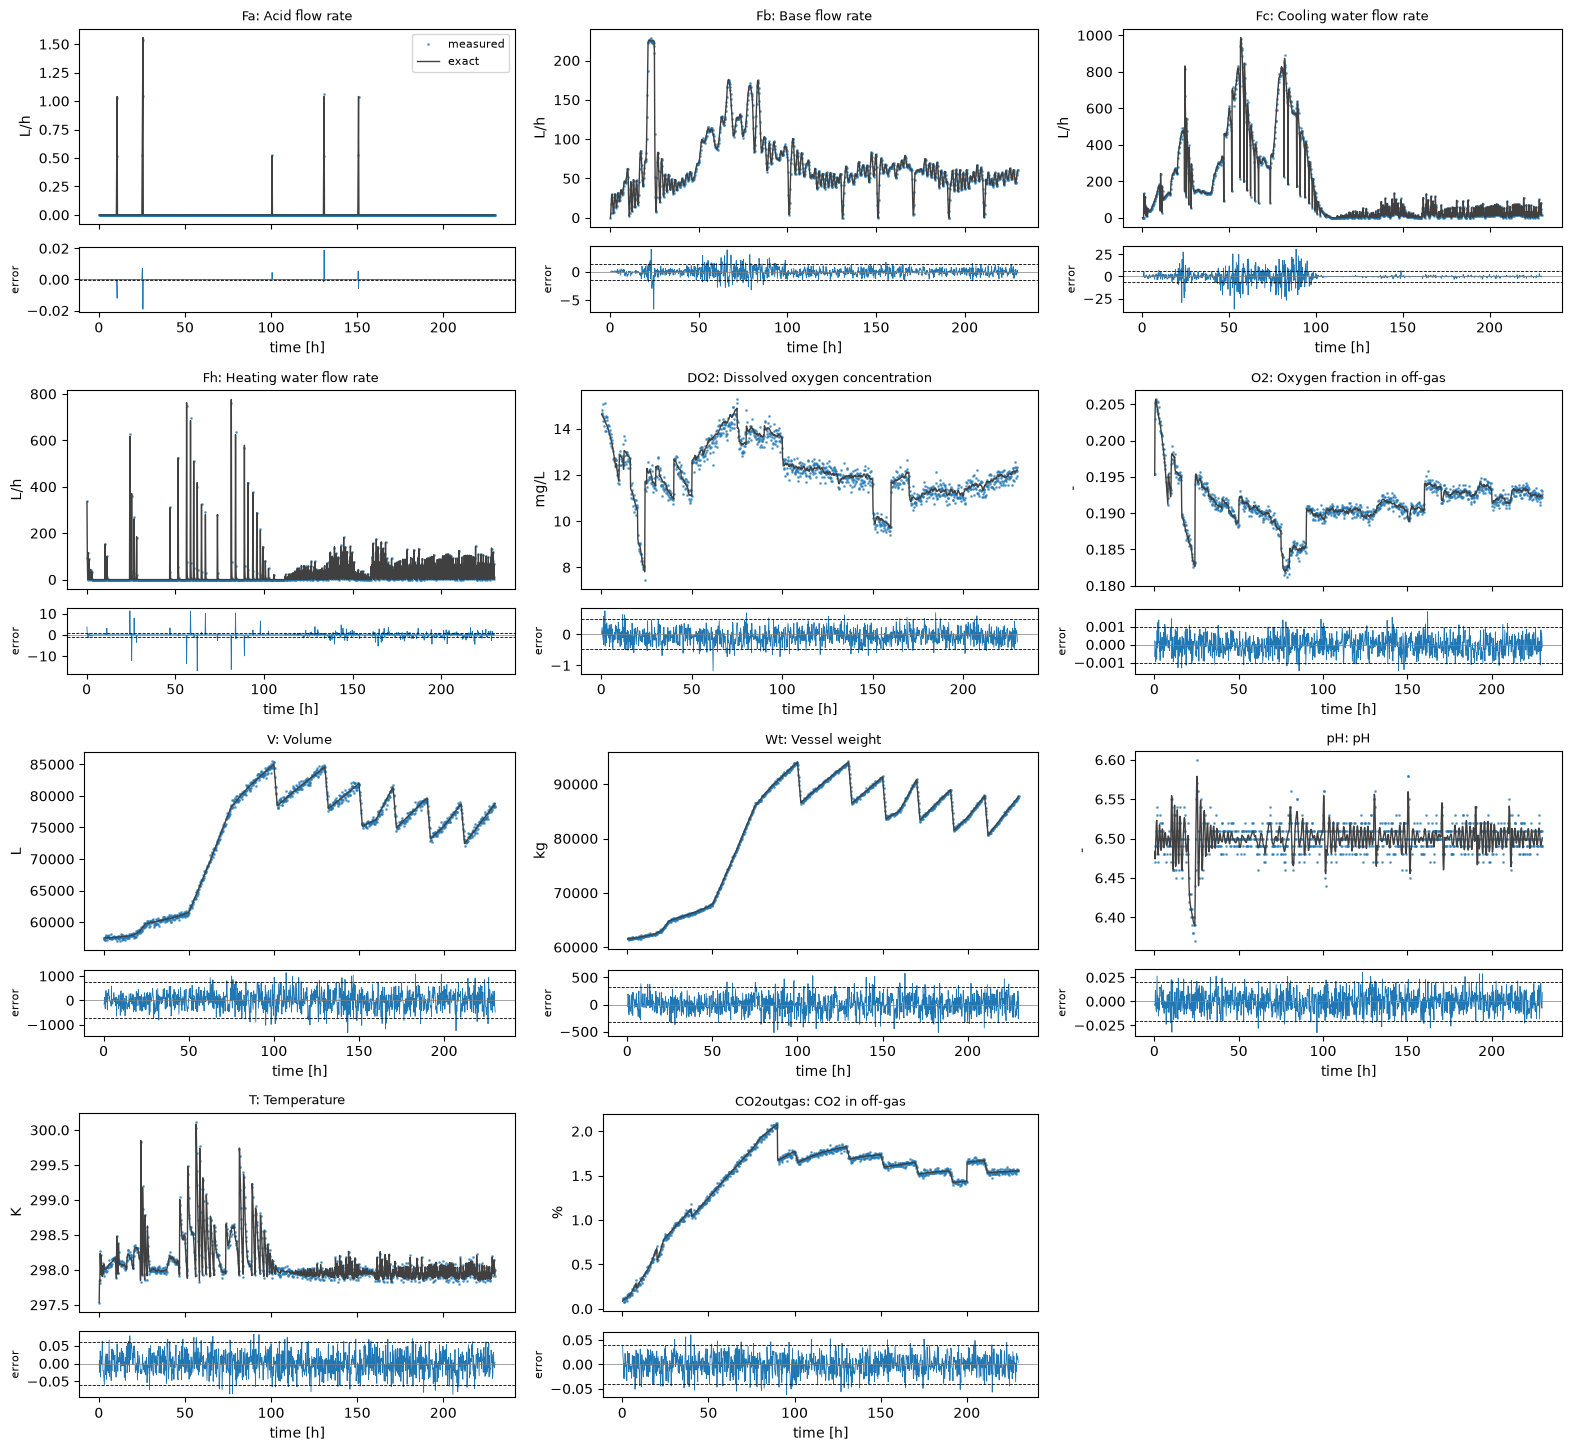

exact (set points): ['Fs', 'Foil', 'Fg', 'pressure', 'discharge', 'Fw', 'Fpaa', 'RPM']


In [4]:
def unit(name):
    return CHANNELS[name][1]


def plot_online(names, ncols=3):
    nrows = -(-len(names) // ncols)
    fig = plt.figure(figsize=(5.2 * ncols, 3.6 * nrows), layout="constrained")
    sub = fig.subfigures(nrows, ncols)
    for sf, name in zip(np.ravel(sub), names, strict=False):
        ax, axe = sf.subplots(2, 1, sharex=True, height_ratios=[3, 1])
        exact = noisy.truth.get(name, noisy[name])
        ax.plot(t, noisy[name], ".", ms=2, alpha=0.6, label="measured")
        ax.plot(t, exact, color="0.25", lw=1, label="exact")
        ax.set_title(f"{name}: {CHANNELS[name][0]}", fontsize=9)
        ax.set_ylabel(unit(name))
        err = noisy[name] - exact
        axe.plot(t, err, lw=0.6)
        sensor = noise.online.get(name)
        if sensor is not None:
            band = 2 * np.hypot(sensor.sd, sensor.rel * np.nanmean(np.abs(exact)))
            if band > 0:
                axe.axhline(band, ls="--", c="k", lw=0.6)
                axe.axhline(-band, ls="--", c="k", lw=0.6)
        axe.axhline(0, c="0.5", lw=0.5)
        axe.set_ylabel("error", fontsize=8)
        axe.set_xlabel("time [h]")
    np.ravel(sub)[0].axes[0].legend(fontsize=8)
    for sf in np.ravel(sub)[len(names) :]:
        sf.set_visible(False)
    plt.show()


plot_online([c for c in ONLINE_CHANNELS if c in noise.online])
print("exact (set points):", [c for c in ONLINE_CHANNELS if c not in noisy.truth])

### Zoom on a few hours

At full scale the noise of a good sensor is invisible. Zoomed in, you see the white noise, the quantisation
steps of `pH` and `T` (0.01) and the 1 rpm steps of the agitator.

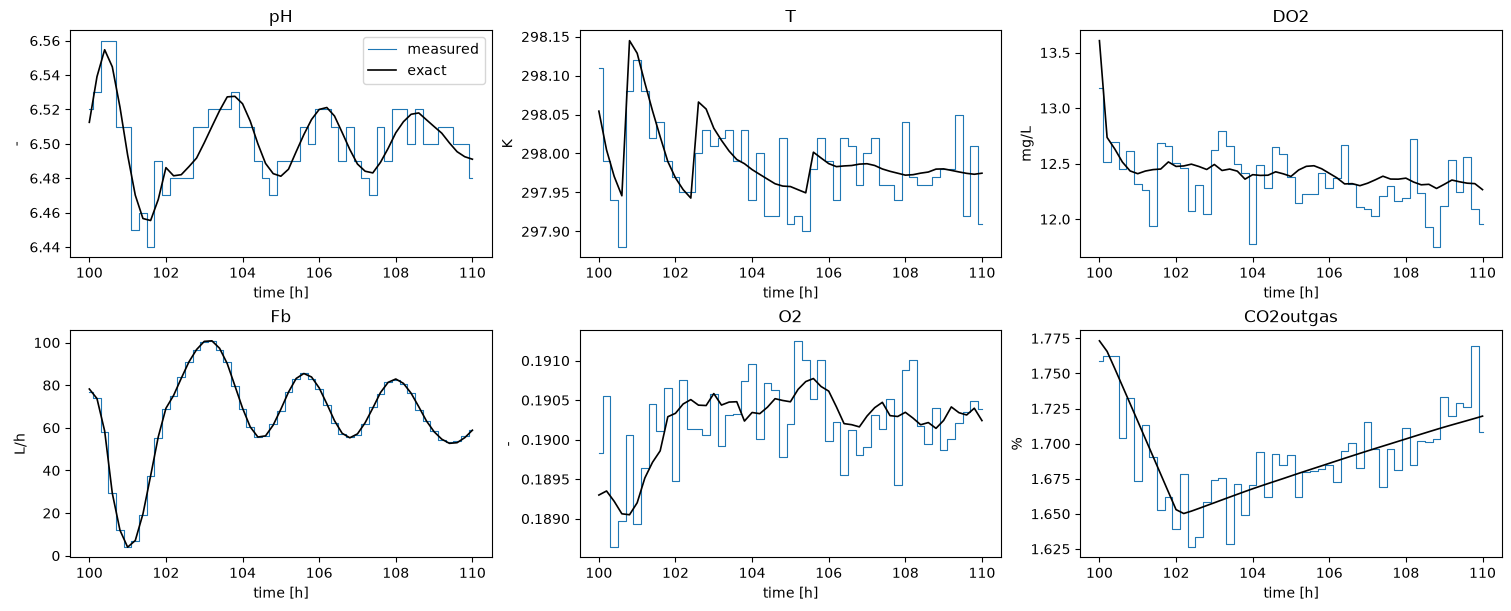

In [5]:
window = (t >= 100) & (t <= 110)
fig, axes = plt.subplots(2, 3, figsize=(15, 6), layout="constrained")
for ax, name in zip(axes.flat, ["pH", "T", "DO2", "Fb", "O2", "CO2outgas"], strict=True):
    ax.step(t[window], noisy[name][window], where="mid", lw=0.8, label="measured")
    ax.plot(t[window], noisy.truth[name][window], "k", lw=1.2, label="exact")
    ax.set_title(name)
    ax.set_ylabel(unit(name))
    ax.set_xlabel("time [h]")
axes[0, 0].legend()
plt.show()

## 2. One error source at a time

Same batch, same seed, dissolved-oxygen probe with only one error source switched on (DO2 is not under control,
so an offset or drift on its reading is physically consistent). The random draws do not depend on the
parameters, so *all sources* is, up to the final rounding, the sum of the panels above it.

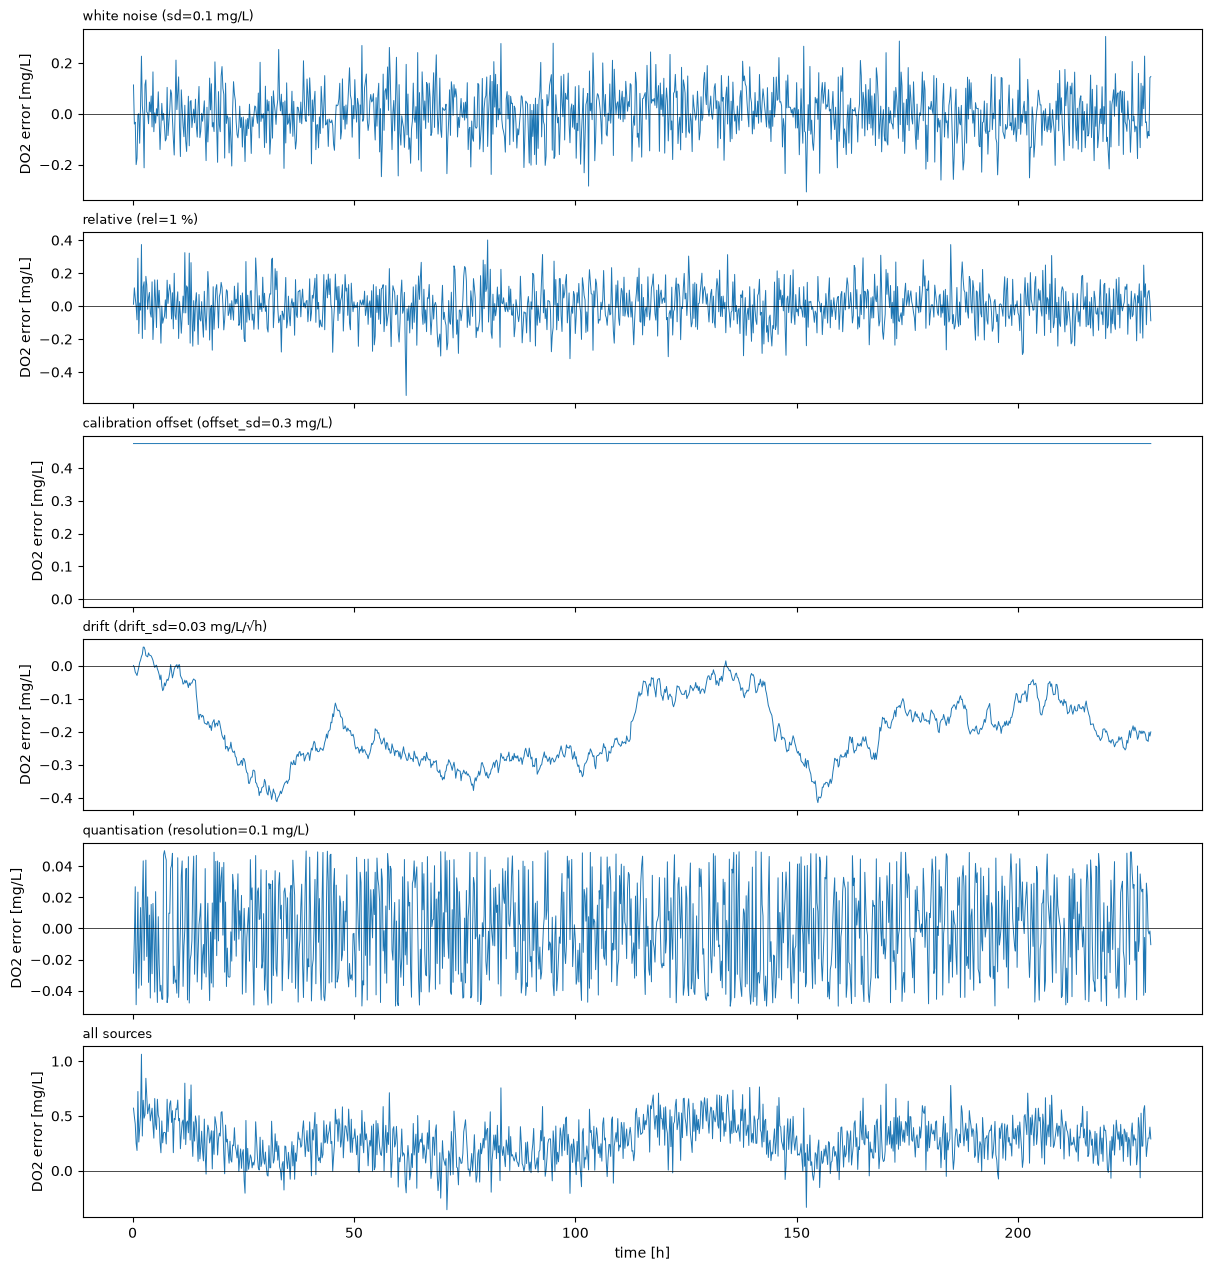

In [6]:
sources = {
    "white noise (sd=0.1 mg/L)": Sensor(sd=0.1),
    "relative (rel=1 %)": Sensor(rel=0.01),
    "calibration offset (offset_sd=0.3 mg/L)": Sensor(offset_sd=0.3),
    "drift (drift_sd=0.03 mg/L/√h)": Sensor(drift_sd=0.03),
    "quantisation (resolution=0.1 mg/L)": Sensor(resolution=0.1),
    "all sources": Sensor(sd=0.1, rel=0.01, offset_sd=0.3, drift_sd=0.03, resolution=0.1),
}
fig, axes = plt.subplots(len(sources), 1, figsize=(12, 2.1 * len(sources)), sharex=True, layout="constrained")
for ax, (label, sensor) in zip(axes, sources.items(), strict=True):
    m = MeasurementNoise(online={"DO2": sensor}).apply(result)
    ax.plot(t, m["DO2"] - result["DO2"], lw=0.7)
    ax.axhline(0, c="k", lw=0.5)
    ax.set_title(label, fontsize=9, loc="left")
    ax.set_ylabel("DO2 error [mg/L]")
axes[-1].set_xlabel("time [h]")
plt.show()

## 3. Statistics over many realisations

The noise of one batch is one random draw. Applying the noise `N_REALISATIONS` times with different seeds to the
same batch gives the distribution of the error, which can be compared with the specification.

For a sensor with `sd` σ, `rel` r, `offset_sd` b, `drift_sd` w and resolution q, the error at time t has

$$\operatorname{Var} = \sigma^2 + r^2 y(t)^2 + b^2 + w^2 t + q^2/12$$

(the last term approximately; bounds can cut the tails of channels near zero). The offset is drawn once per
realisation, so with 600 realisations its standard deviation is estimated to about ±3 %: the check allows 10 %.
Rounding a constant value (`RPM` = 100 to 1 rpm) is not random, so sensors with only a resolution are left out.

In [7]:
# Keep only the errors of the measured channels: (realisation, sample) arrays, float32 to save memory.
measured = sorted(noisy.truth)
_err = {name: np.empty((N_REALISATIONS, len(t)), dtype=np.float32) for name in measured}
for i in range(N_REALISATIONS):
    r = noise.apply(result, seed=10_000 + i)
    for name in measured:
        _err[name][i] = r[name] - r.truth[name]


def errors(name):
    return _err[name].astype(float)


def expected_sd(name, sensor):
    y = result[name]
    return np.sqrt(
        sensor.sd**2 + (sensor.rel * y) ** 2 + sensor.offset_sd**2 + sensor.drift_sd**2 * t + sensor.resolution**2 / 12
    )


rows = []
for name, sensor in noise.online.items():
    if sensor.sd == sensor.rel == sensor.offset_sd == sensor.drift_sd == 0:
        continue
    err = errors(name)
    exp_sd = expected_sd(name, sensor)
    inside = (exp_sd > 0) & (result[name] > 3 * exp_sd) if sensor.lo == 0 else exp_sd > 0
    if name == "discharge":
        inside = (exp_sd > 0) & (result[name] < -3 * exp_sd)
    if not inside.any():
        continue
    rows.append(
        {
            "channel": name,
            "expected sd (mean)": exp_sd[inside].mean(),
            "observed sd (mean)": err[:, inside].std(axis=0).mean(),
            "mean error": err[:, inside].mean(),
        }
    )
stats = pd.DataFrame(rows).set_index("channel")
stats["observed / expected"] = stats["observed sd (mean)"] / stats["expected sd (mean)"]
display(stats.style.format("{:.4g}"))
assert stats["observed / expected"].between(0.9, 1.1).all(), stats
print("OK: observed standard deviations within 10 % of the specification")

,expected sd (mean),observed sd (mean),mean error,observed / expected
channel,,,,
T,0.03014,0.03009,5.282e-05,0.9984
pH,0.01041,0.0104,-6.227e-06,0.9995
DO2,0.2659,0.2653,0.0002368,0.9979
O2,0.0005,0.0004988,1.675e-06,0.9975
CO2outgas,0.02,0.01999,2.454e-05,0.9994
Fa,0.008306,0.008287,-0.0002333,0.9977
Fb,0.6773,0.6773,-0.0003141,0.9999
Fc,3.335,3.329,0.004147,0.9984
Fh,0.5143,0.5139,-0.002699,0.9992


OK: observed standard deviations within 10 % of the specification


### Error distribution and growth of drift

Left: histogram of the normalised `CO2outgas` error (error / expected sd), a sensor with white noise only,
against the standard normal density. Right: for `DO2`, the observed error spread over time (shaded: 5–95 % of realisations) and the expected ±1.645 sd: the
band widens as the membrane drifts.

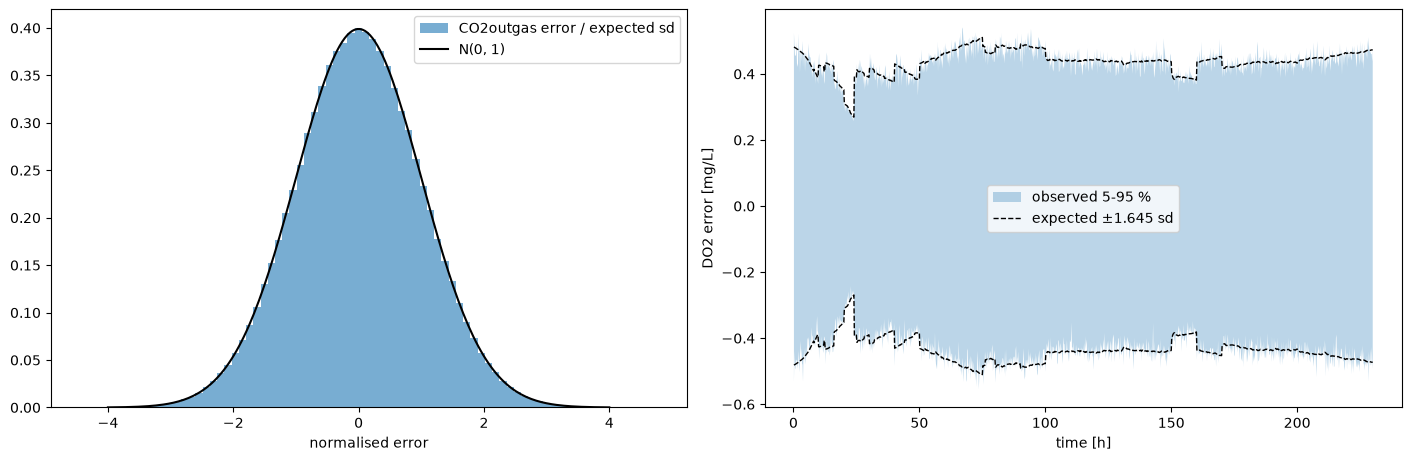

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5), layout="constrained")
z = (errors("CO2outgas") / expected_sd("CO2outgas", noise.online["CO2outgas"])).ravel()
a1.hist(z, bins=80, density=True, alpha=0.6, label="CO2outgas error / expected sd")
x = np.linspace(-4, 4, 200)
a1.plot(x, np.exp(-(x**2) / 2) / np.sqrt(2 * np.pi), "k", label="N(0, 1)")
a1.legend()
a1.set_xlabel("normalised error")

e = errors("DO2")
lo, hi = np.percentile(e, [5, 95], axis=0)
s = expected_sd("DO2", noise.online["DO2"])
a2.fill_between(t, lo, hi, alpha=0.3, label="observed 5-95 %")
a2.plot(t, 1.645 * s, "k--", lw=1, label="expected ±1.645 sd")
a2.plot(t, -1.645 * s, "k--", lw=1)
a2.set_xlabel("time [h]")
a2.set_ylabel("DO2 error [mg/L]")
a2.legend()
plt.show()

## 4. Off-gas rates

`OUR` and `CER` are not given noise of their own: like in a plant, they are computed from the measured aeration
rate and off-gas composition. Their errors are therefore large (a small error on the O₂ fraction is a large
error on the O₂ *difference* between inlet and outlet) and correlated with the gas measurement.

OK: OUR and CER equal the off-gas formula applied to the measured Fg, O2 and CO2outgas


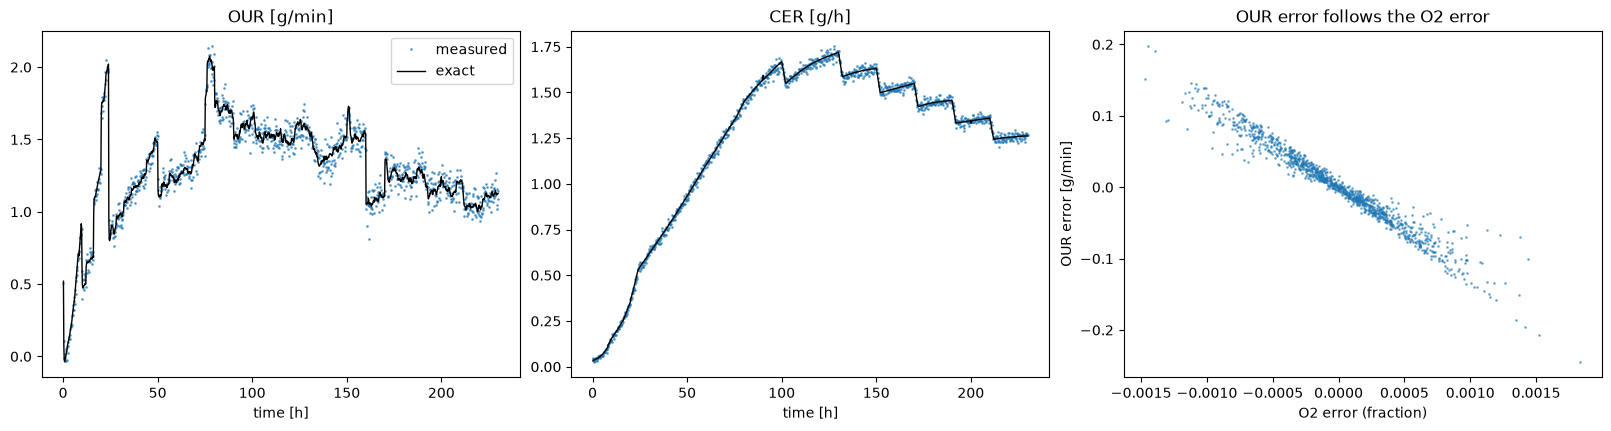

In [9]:
our, cer = off_gas_rates(noisy["Fg"], noisy["O2"], noisy["CO2outgas"])
assert np.array_equal(noisy["OUR"], our) and np.array_equal(noisy["CER"], cer)
print("OK: OUR and CER equal the off-gas formula applied to the measured Fg, O2 and CO2outgas")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), layout="constrained")
for ax, name in zip(axes[:2], ["OUR", "CER"], strict=True):
    ax.plot(t, noisy[name], ".", ms=2, alpha=0.6, label="measured")
    ax.plot(t, noisy.truth[name], "k", lw=1, label="exact")
    ax.set_title(f"{name} [{unit(name)}]")
    ax.set_xlabel("time [h]")
axes[0].legend()
axes[2].plot(noisy["O2"] - noisy.truth["O2"], noisy["OUR"] - noisy.truth["OUR"], ".", ms=2, alpha=0.5)
axes[2].set_xlabel("O2 error (fraction)")
axes[2].set_ylabel("OUR error [g/min]")
axes[2].set_title("OUR error follows the O2 error")
plt.show()

## 5. Lab results

Continuous line: exact process value (`P`, `X`, `PAA`, `NH3`, `Viscosity`). Open circles: lab results without
noise, plotted at the time the broth was **sampled** (they sit on the line). Filled dots: lab results with assay
error, with ±2 sd error bars from the assay specification. The schedule (1 h, every 12 h, end of batch) and the
reporting delay are unchanged.

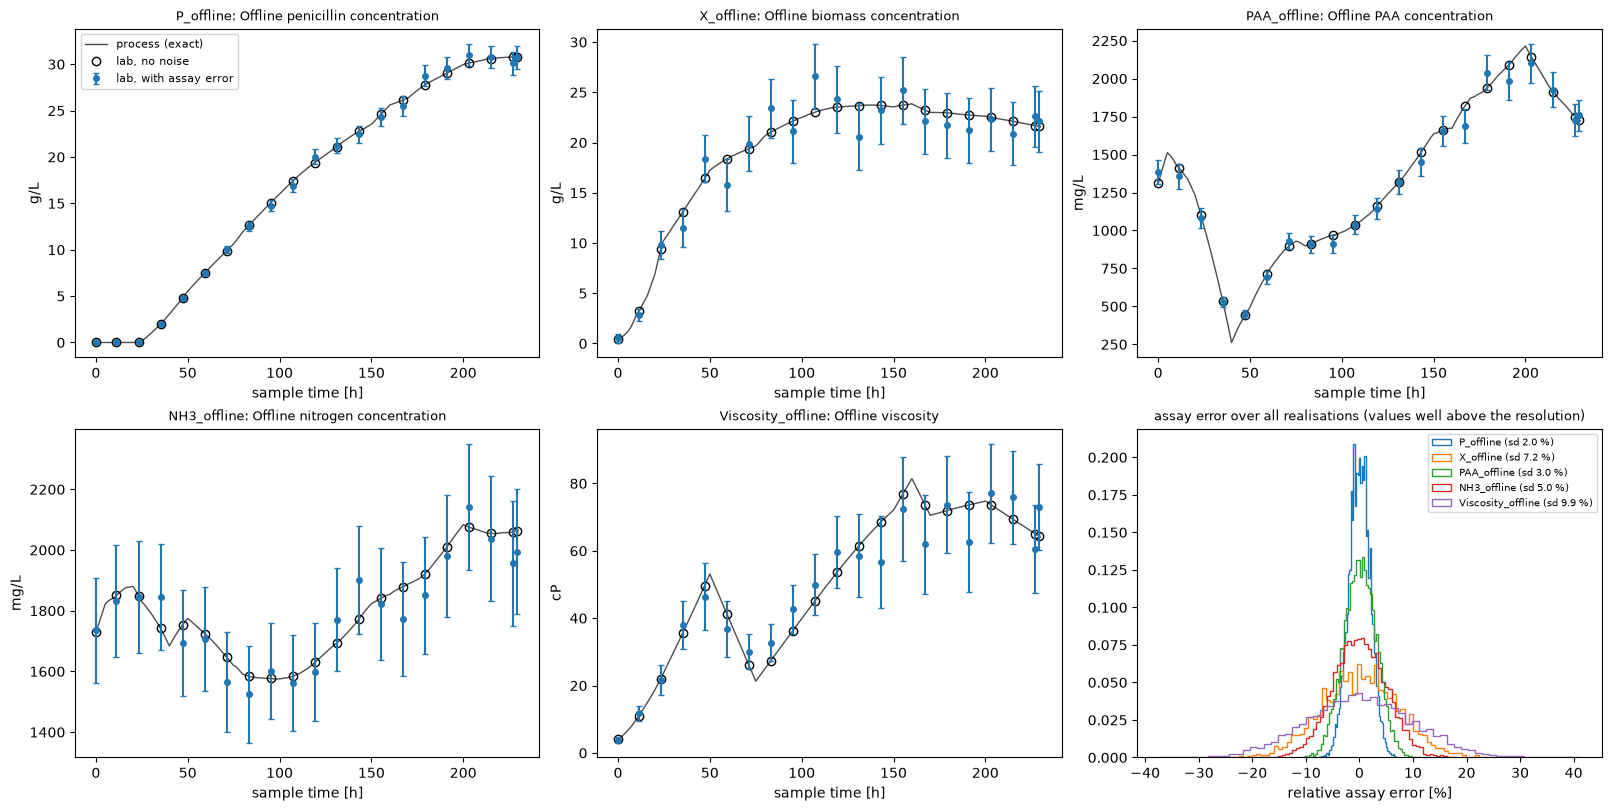

OK: lab results reported at the same samples as without noise


In [10]:
delay_h = config.offline_delay_steps * (t[1] - t[0])
fig, axes = plt.subplots(2, 3, figsize=(16, 8), layout="constrained")
for ax, lab in zip(axes.flat, LAB_CHANNELS, strict=False):
    base = lab.removesuffix("_offline")
    rep = ~np.isnan(result[lab])
    ts = t[rep] - delay_h
    sensor = noise.lab[lab]
    exact = noisy.truth[lab][rep]
    sd = np.sqrt(sensor.sd**2 + (sensor.rel * exact) ** 2 + sensor.offset_sd**2 + sensor.resolution**2 / 12)
    ax.plot(t, result[base], color="0.3", lw=1, label="process (exact)")
    ax.plot(ts, exact, "o", mfc="none", c="k", label="lab, no noise")
    ax.errorbar(ts, noisy[lab][rep], yerr=2 * sd, fmt="o", ms=4, capsize=2, label="lab, with assay error")
    ax.set_title(f"{lab}: {CHANNELS[lab][0]}", fontsize=9)
    ax.set_ylabel(unit(lab))
    ax.set_xlabel("sample time [h]")
axes.flat[0].legend(fontsize=8)

ax = axes.flat[-1]  # parity plot, relative error of every assay over all realisations
for lab in LAB_CHANNELS:
    rep = ~np.isnan(result[lab]) & (result[lab] > 20 * noise.lab[lab].resolution)  # skip values ~ resolution
    rel = (errors(lab)[:, rep] / result[lab][rep]).ravel()
    ax.hist(rel * 100, bins=60, histtype="step", density=True, label=f"{lab} (sd {rel.std() * 100:.1f} %)")
ax.set_xlabel("relative assay error [%]")
ax.set_title("assay error over all realisations (values well above the resolution)", fontsize=9)
ax.legend(fontsize=7)
plt.show()

for lab in LAB_CHANNELS:
    assert np.array_equal(np.isnan(noisy[lab]), np.isnan(result[lab]))
print("OK: lab results reported at the same samples as without noise")

## 6. Reproducibility and guarantees

In [11]:
again = noise.apply(result, seed=NOISE_SEED)
assert all(np.array_equal(again[c], noisy[c], equal_nan=True) for c in noisy.truth)
print("OK: same seed -> identical measurements")

other = noise.apply(result, seed=999)
assert not np.array_equal(other["pH"], noisy["pH"])
print("OK: different seed -> different measurements")

fresh = Simulator(config=config).run(seed=SEED)
assert all(np.array_equal(fresh[c], result[c], equal_nan=True) for c in result.data)
assert all(np.array_equal(noisy.truth[c], fresh[c], equal_nan=True) for c in noisy.truth)
print("OK: the simulation is untouched; noisy.truth holds the exact values")

hidden = [c for c in CHANNELS if c not in noisy.truth]
assert all(np.array_equal(noisy[c], result[c], equal_nan=True) for c in hidden)
print(f"OK: {len(hidden)} channels without a sensor (set points Fs, Fg, ...; states S, P, X, ...) are exact")

without_T = noise.with_(T=None).apply(result, seed=NOISE_SEED)
assert np.array_equal(without_T["pH"], noisy["pH"]) and np.array_equal(without_T["T"], result["T"])
print("OK: removing one sensor leaves the noise of the others unchanged")

zero = noise.scaled(0).apply(result)
print(
    "max |error| with scaled(0) (quantisation only):",
    {c: float(np.nanmax(np.abs(zero[c] - result[c]))) for c in ["pH", "T", "DO2", "Fb"]},
)

OK: same seed -> identical measurements
OK: different seed -> different measurements


OK: the simulation is untouched; noisy.truth holds the exact values
OK: 37 channels without a sensor (set points Fs, Fg, ...; states S, P, X, ...) are exact
OK: removing one sensor leaves the noise of the others unchanged
max |error| with scaled(0) (quantisation only): {'pH': 0.004993487425514864, 'T': 0.004997081869134945, 'DO2': 0.0, 'Fb': 0.0}


### Noise level

`scaled(k)` multiplies every random error. Same seed, so the shapes match and only the amplitude changes.

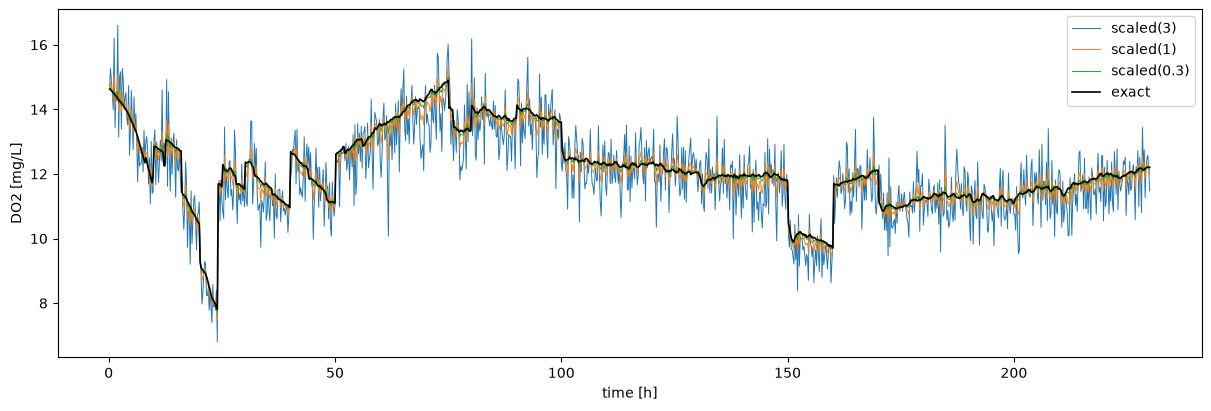

In [12]:
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
for k in [3, 1, 0.3]:
    ax.plot(t, MeasurementNoise.typical().scaled(k).apply(result)["DO2"], lw=0.7, label=f"scaled({k})")
ax.plot(t, result["DO2"], "k", lw=1.2, label="exact")
ax.set_ylabel("DO2 [mg/L]")
ax.set_xlabel("time [h]")
ax.legend()
plt.show()

## 7. A campaign with noise

Campaigns take `measurement_noise=`. Channels then hold the measurements and `<channel>_true` the exact values;
`camp.online()` returns only measurements, and `camp.lab` carries `<assay>` and `<assay>_true`.

In [13]:
camp = scenarios.fault_campaign(
    n_normal=2,
    n_per_fault=0,
    seed=0,
    n_jobs=1,
    config=SimulationConfig(raman_mode=RamanMode.OFF, batch_length_h=60.0),
    measurement_noise=noise,
)
print("online columns:", list(camp.online().columns)[:10], "...")
print("true columns:", [c for c in camp.samples.columns if c.endswith("_true")][:8], "...")
camp.lab.head()

online columns: ['batch_id', 'time_h', 'kind', 'fault', 'fault_active', 'Fs', 'Foil', 'Fg', 'pressure', 'discharge'] ...
true columns: ['T_true', 'pH_true', 'DO2_true', 'O2_true', 'CO2outgas_true', 'Fa_true', 'Fb_true', 'Fc_true'] ...


,batch_id,sample_time_h,available_time_h,P,X,PAA,NH3,Viscosity,P_true,X_true,PAA_true,NH3_true,Viscosity_true
0,1,0.2,1.0,0.00,0.8,1386.0,1735.0,3.9,0.001000,0.481590,1314.476772,1730.310336,4.080538
1,1,11.2,12.0,0.00,3.1,1356.0,1832.0,11.8,0.000969,3.200918,1414.134360,1850.737751,10.931270
2,1,23.2,24.0,0.00,10.1,1080.0,1846.0,21.7,0.000917,9.367711,1103.664240,1849.179340,22.004277
3,1,35.2,36.0,2.03,11.5,527.0,1845.0,38.0,1.997703,13.096894,533.748087,1741.382098,35.553447
4,1,47.2,48.0,4.75,19.0,447.0,1694.0,46.4,4.806365,16.427427,440.051432,1753.467977,49.700664
